# ===============================
# 03_MLModels_XGBoost_RF.ipynb
# ===============================

Dataset shape: (844338, 32)
Train shape: (754, 27), Test shape: (27, 27)

===== Random Forest Performance =====
MAE: 286.23
RMSE: 357.14


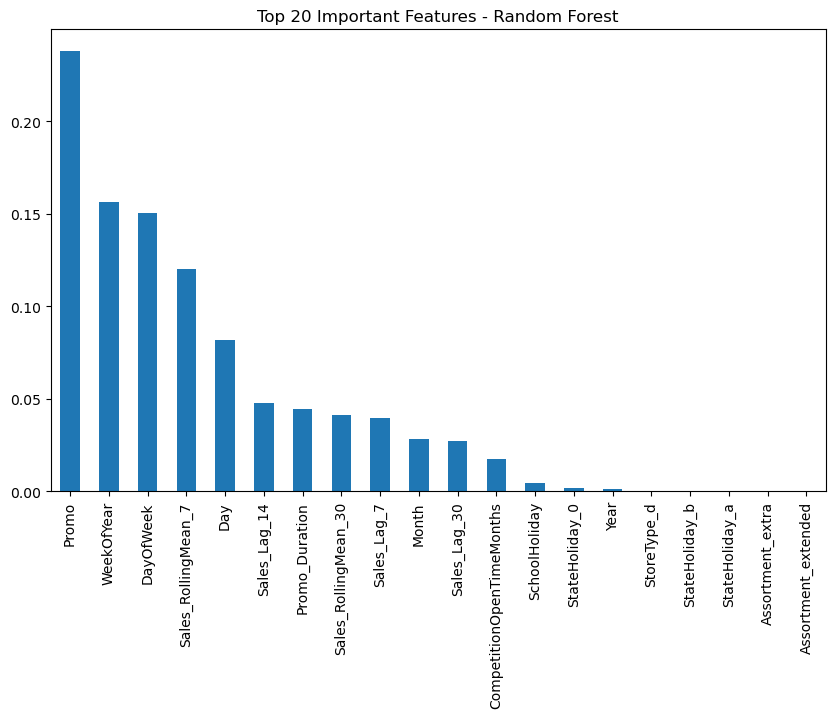


===== XGBoost Performance =====
MAE: 292.97
RMSE: 368.47


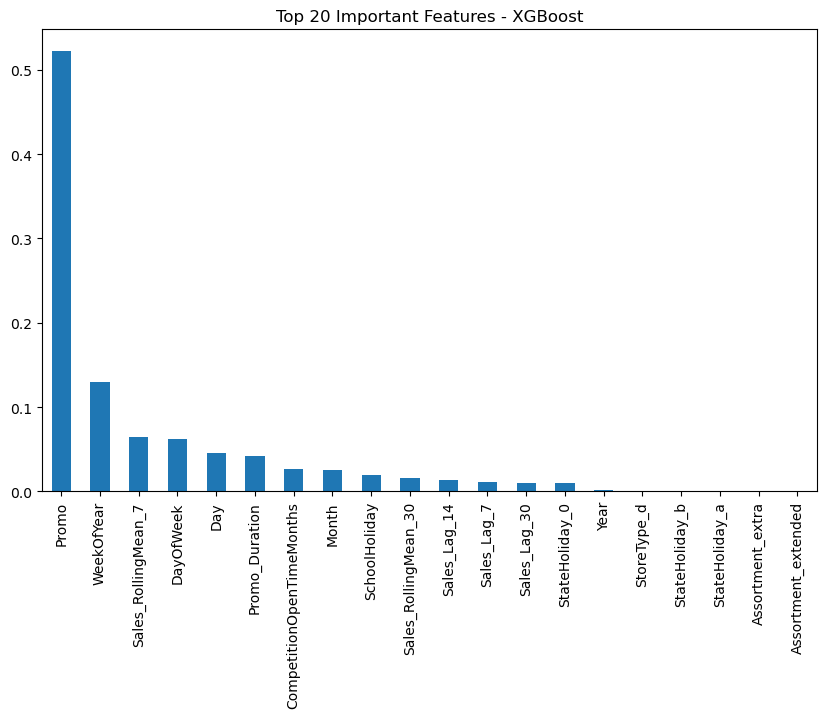


===== Final Model Comparison =====
Prophet Baseline RMSE: ~780
Random Forest RMSE: 357.14
XGBoost RMSE: 368.47


In [3]:
# ===============================
# 03_MLModels_XGBoost_RF.ipynb
# ===============================

# 1. Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error

# 2. Load Feature-Engineered Data
df = pd.read_csv('/Users/ronitgandhi/Portfolio Projects/rossmann_forecasting/data/feature_engineered_rossmann.csv', parse_dates=['Date'])
print(f"Dataset shape: {df.shape}")

# 3. Filter Store 1 (same as earlier)
store_id = 1
df_store = df[df['Store'] == store_id].copy()

# 4. Define Features and Target
# Drop non-usable columns
features = df_store.drop(columns=['Sales', 'Customers', 'Date', 'Store', 'PromoInterval'])

target = df_store['Sales']

# 5. Train-Test Split
X_train = features[df_store['Date'] < '2015-07-01']
X_test = features[df_store['Date'] >= '2015-07-01']
y_train = target[df_store['Date'] < '2015-07-01']
y_test = target[df_store['Date'] >= '2015-07-01']

print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")

# ===================================================
# RANDOM FOREST REGRESSOR
# ===================================================

# 6. Train Random Forest
rf = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

# 7. Predict
y_pred_rf = rf.predict(X_test)

# 8. Evaluate Random Forest
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = mean_squared_error(y_test, y_pred_rf, squared=False)

print("\n===== Random Forest Performance =====")
print(f"MAE: {mae_rf:.2f}")
print(f"RMSE: {rmse_rf:.2f}")

# 9. Feature Importance (RF)
importances_rf = pd.Series(rf.feature_importances_, index=X_train.columns)
importances_rf = importances_rf.sort_values(ascending=False)

plt.figure(figsize=(10,6))
importances_rf.head(20).plot(kind='bar')
plt.title('Top 20 Important Features - Random Forest')
plt.show()

# ===================================================
# XGBOOST REGRESSOR
# ===================================================

# 10. Train XGBoost
xgb = XGBRegressor(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1)
xgb.fit(X_train, y_train)

# 11. Predict
y_pred_xgb = xgb.predict(X_test)

# 12. Evaluate XGBoost
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
rmse_xgb = mean_squared_error(y_test, y_pred_xgb, squared=False)

print("\n===== XGBoost Performance =====")
print(f"MAE: {mae_xgb:.2f}")
print(f"RMSE: {rmse_xgb:.2f}")

# 13. Feature Importance (XGB)
importances_xgb = pd.Series(xgb.feature_importances_, index=X_train.columns)
importances_xgb = importances_xgb.sort_values(ascending=False)

plt.figure(figsize=(10,6))
importances_xgb.head(20).plot(kind='bar')
plt.title('Top 20 Important Features - XGBoost')
plt.show()

# ===================================================
# Summary of All Models
# ===================================================

print("\n===== Final Model Comparison =====")
print(f"Prophet Baseline RMSE: ~780")
print(f"Random Forest RMSE: {rmse_rf:.2f}")
print(f"XGBoost RMSE: {rmse_xgb:.2f}")
